<a href="https://colab.research.google.com/github/anniiexp/MAT422/blob/main/3_5_3_6_KMeans_and_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT422 - Section 3.5/3.6: K-Means and Support Vector Machines

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_classification
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

np.set_printoptions(precision=4, suppress=True)

## Topics:


*   K-Means
*   Support Vector Machines



# 3.5 K-Means

K-means is an algorithm that groups $n$ data points $x_1, \dots, x_n \in \mathbb{R}^d$ into $k$ clusters. No labels are given; the algorithm discovers structure on its own. It chooses the centroids and assigments to minimize the inertia:
$$
J = \sum_{i=1}^{n} \lVert x_i - \mu_{c_i} \rVert^2
$$

The algorith alternates 2 steps until nothing changes:
1. **Assign:** put each point in the cluster whose centroid is closest.
2. **Update:** move each centroid to the mean of the points assigned to it, $\mu_j = \frac{1}{|C_j|}\sum_{x_i \in C_j} x_i$.

Each step can only lower $J$ (or keep the same), so the algorithm always converges. This is why we run it several times from different starting points (`n_init`) and keep the best result.

Cluster centers (mu_j):
[[-8.3662  5.5366]
 [-0.0036 -8.7793]
 [ 9.575   0.6346]
 [-1.4152  4.4872]]
Points per cluster: [60 60 60 60]

Inertia from sklearn: 371.1791860706287
Inertia computed by hand: 371.1791860706286
Match? True

Each centroid = mean of its cluster? True


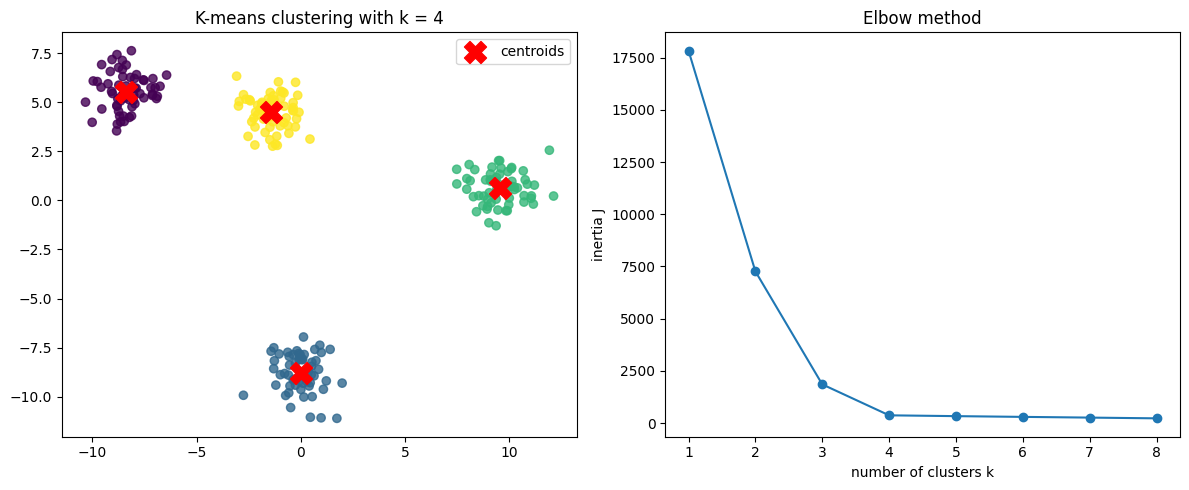

In [13]:
X, true_labels = make_blobs(n_samples=240, centers=4, cluster_std=0.9, random_state=7)

k = 4
kmeans = KMeans(n_clusters=k, n_init=10, random_state=7)
cluster_labels = kmeans.fit_predict(X)
centers = kmeans.cluster_centers_

print("Cluster centers (mu_j):")
print(centers)
print("Points per cluster:", np.bincount(cluster_labels))

# compute inertia J by hand compare
J_manual = np.sum((X - centers[cluster_labels])**2)
print("\nInertia from sklearn:", kmeans.inertia_)
print("Inertia computed by hand:", J_manual)
print("Match?", np.isclose(J_manual, kmeans.inertia_))

# each centroid should equal mean to the points assigned to it
means = np.array([X[cluster_labels == j].mean(axis=0) for j in range(k)])
print("\nEach centroid = mean of its cluster?", np.allclose(means, centers))

# plot 1
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X[:, 0], X[:, 1], c=cluster_labels, cmap="viridis", alpha=0.8)
axes[0].scatter(centers[:, 0], centers[:, 1], marker="X", s=250, color="red", label="centroids")
axes[0].set_title(f"K-means clustering with k = {k}")
axes[0].legend()

# plot 2
ks = range(1, 9)
inertias = [KMeans(n_clusters=j, n_init=10, random_state=7).fit(X).inertia_ for j in ks]
axes[1].plot(ks, inertias, marker="o")
axes[1].set_xlabel("number of clusters k")
axes[1].set_ylabel("inertia J")
axes[1].set_title("Elbow method")
plt.tight_layout()
plt.show()

The code above, it generates 240 points from 4 Gaussian blobs, then runs K-means with $k = 4$. The labels from `make_blobs` were never given to the algorithm; it found the groups using only distances.

For the inertia, the hand-computed value of $J = \sum \lVert x_i - \mu_{c_i}\rVert^2$ matches `kmeans.inertia_`. This confirms that inertia is exactly the objective function from above: the total squared distance from every point to its own centroid.

Every centroid equals the mean of the points in its cluster. This is the update step of the algorithm and it holds at onvergence because the centroids stop moving.
- In the left plot, the red X's sit in the middle of each colored group, and points are colored by whichever centroid is nearest. Where two blobs overlap, the boundary between colors is a straight line halfway between the two centroids.
- In the right plot, inertia always decreases as $k$ increases (more centroids means points are closer to one). But the drop is large up to $k = 4$ and small after that. This "elbow" at $k = 4$ suggests 4 is a natural number of clusters, which agrees with how the data was generated.

Therefore, K-means minimizes within-cluster squared distance, so it works best when clusters are roughly round and similar in size. Choosing $k$ is not automatic, though the elbow plot is one way to make that choice from the data.

# 3.6 Support Vector Machines

A support vector machine is a learning method used to classify data into two groups. Unlike K-means, which finds groups on its own, an SVM is trained on points that already have labels, and its job is to learn a boundary that separates the two classes so that new points can be classified correctly.

There are usually many lines that could separate the two classes, so the SVM needs a way to choose the best one. Its answer is to pick the line with the **largest margin**, where the margin is the gap between the two parallel lines $f(x) = 1$ and $f(x) = -1$. The width of this gap works out to $2 / \lVert w \rVert$, so making the margin wide is the same as making $\lVert w \rVert$ small. A wide margin is desirable because it leaves room for error when classifying new data.

Real data often can't be separated perfectly, so in practice we use a *soft-margin* SVM, which allows some points to fall inside the margin or even on the wrong side, at a cost.

Finally, the points that lie on or inside the margin are called **support vectors**, which is where the method gets its name. They are the only points that actually determine the boundary. Every other point could be moved around (as long as it stays outside the margin) and the solution would not change at all.

w = [2.3569 1.8496]
b = -1.392
Margin width (2/||w||): 0.6676
Training accuracy: 1.0
Number of support vectors: 12
Hand calculation matches? True


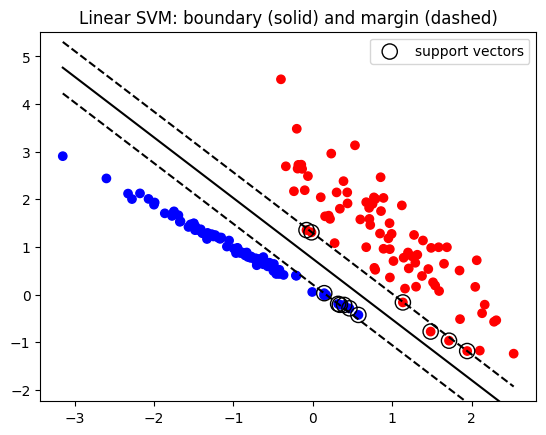

In [14]:
Xc, yc = make_classification(n_samples=160, n_features=2, n_redundant=0, n_informative=2,
                             n_clusters_per_class=1, class_sep=1.0, random_state=11)

svm = SVC(kernel="linear", C=1.0)
svm.fit(Xc, yc)

w = svm.coef_[0]
b = svm.intercept_[0]
print("w =", w)
print("b =", round(b, 4))
print("Margin width (2/||w||):", round(2 / np.linalg.norm(w), 4))
print("Training accuracy:", accuracy_score(yc, svm.predict(Xc)))
print("Number of support vectors:", len(svm.support_vectors_))

# Check: f(x) = w.x + b by hand matches sklearn
print("Hand calculation matches?", np.allclose(Xc @ w + b, svm.decision_function(Xc)))

# Plot: draw the line w1*x1 + w2*x2 + b = c, solved for x2
x1 = np.linspace(Xc[:, 0].min(), Xc[:, 0].max(), 100)
for c, style in [(0, "-"), (1, "--"), (-1, "--")]:
    x2 = (c - b - w[0] * x1) / w[1]
    plt.plot(x1, x2, "k" + style)

plt.scatter(Xc[:, 0], Xc[:, 1], c=yc, cmap="bwr")
plt.scatter(svm.support_vectors_[:, 0], svm.support_vectors_[:, 1], s=120,
            facecolors="none", edgecolors="black", label="support vectors")
plt.ylim(Xc[:, 1].min() - 1, Xc[:, 1].max() + 1)
plt.title("Linear SVM: boundary (solid) and margin (dashed)")
plt.legend()
plt.show()

This is a linear SVM on 160 labeled points from two classes. The model found

$$w = (2.3569,\ 1.8496), \qquad b = -1.392,$$

so the decision boundary (the solid black line) is

$$2.3569\,x_1 + 1.8496\,x_2 - 1.392 = 0.$$

Points where $f(x) = w \cdot x + b$ is positive are classified as red, and points where it is negative are classified as blue. Solving for $x_2$ gives a slope of $-2.3569/1.8496 \approx -1.27$, which is why the boundary slants downward, with the red class above and to the right of it.

The dashed lines are where $f(x) = 1$ and $f(x) = -1$, and the space between them is the margin. Its width is $2/\lVert w \rVert = 0.6676$. The SVM chose this particular line because it makes this margin as wide as possible while still separating the classes.

The training accuracy is 1.0, meaning every one of the 160 points landed on the correct side of the line, so these two classes are linearly separable. However, perfect training accuracy does not guarantee the model will classify new points perfectly.

Only 12 of the 160 points are support vectors (the circled points). They all sit on or near the dashed lines, close to the boundary. These 12 points alone determine where the line goes; the other 148 points could be moved and the boundary would not change.

The check printed `True`, confirming that the classifier is just the linear function $f(x) = w \cdot x + b$: computing it by hand with the printed $w$ and $b$ gives the same values as scikit-learn.

# Reflection



*   K-Means: Generated 240 points from 4 blobs (changed from the class example's 180 points and 3 centers, with `cluster_std` raised from 0.7 to 0.9) and fit K-means with $k = 4$. The algorithm split the data evenly into 4 clusters of 60 points each, with an inertia of 371.18, and computing $J = \sum \lVert x_i - \mu_{c_i} \rVert^2$ by hand gave the same value. Checked that each centroid equals the mean of the points assigned to it. The elbow plot showed inertia falling from about 17,800 at $k = 1$ down to 371.18 at $k = 4$, then flattening out, matching the number of blobs used to generate the data.
*   SVM: Fit a linear SVM to 160 points and changed `class_sep` from 1.3 to 1.0 so the classes sit closer together. The fitted boundary was $2.3569\,x_1 + 1.8496\,x_2 - 1.392 = 0$ with a margin width of $2/\lVert w \rVert = 0.6676$. The training accuracy was 1.0, so the classes were separable. Only 12 of the 160 points were support vectors, showing the boundary depends only on the points closest to it. The check confirmed the classifier is just $f(x) = w \cdot x + b$, since the hand calculation matched scikit-learn.

